# The Wanli era (1573–1620)
A use case on one reign: who was active in Ming China under the Wanli Emperor, and what their biographies look like.
An individual is included when they are matched to the **Ming Dynasty** polity (`humans_clean_enriched_v3`) and their **active life** (`cultura_enriched_v3.2`) overlaps 1573–1620.

In [1]:
import json
import random
import tempfile

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from matplotlib.patches import Patch
from shapely.geometry import shape
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'
COUNTRIES_PATH = '../../data/ne_110m_admin_0_countries.geojson'

POLITY_NAME = 'Ming Dynasty'
WANLI_START, WANLI_END = 1573, 1620
SERIES_START, SERIES_END = 1520, 1680
FEMALE_QID = 'Q6581072'
TOP_TIMELINE = 40
TOP_OCCUPATIONS = 15
TOP_BIOGRAPHIES = 30

GENERIC_OCCUPATION = 'politician'
TOP_GROUPS = 7
OCCUPATION_PALETTE = [ORANGE, BLUE, GREEN, PURPLE, RED, TEAL, PINK]
OTHER_OCCUPATION, NO_OCCUPATION = 'other occupation', 'no occupation'
WANLI_SHADE = {'color': PALE_BLUE, 'alpha': 0.6, 'lw': 0}
MAP_EXTENT = (95, 128, 17, 45)

apply_style()

## External data
Country outlines (Natural Earth, 1:110m) for the map background. The Wanli reign dates (1573–1620) are the only constants not read from the database.

## Load data
### Ming individuals active during the Wanli era

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

con.sql('''
    CREATE TEMP TABLE ming_individuals AS
    SELECT DISTINCT entity.qid AS qid
    FROM   (SELECT entity, unnest(polity) AS polity_match FROM polity_db.individual_enriched)
    WHERE  polity_match.polity.name = $polity
''', params={'polity': POLITY_NAME})

con.sql('''
    CREATE TEMP TABLE wanli_individuals AS
    SELECT individual_enriched.entity.qid                AS qid,
           individual_enriched.start_of_active_life.year AS active_start,
           individual_enriched.end_of_active_life.year   AS active_end
    FROM   individual_enriched
    JOIN   ming_individuals ON ming_individuals.qid = individual_enriched.entity.qid
    WHERE  individual_enriched.start_of_active_life.year <= $end
      AND  individual_enriched.end_of_active_life.year   >= $start
''', params={'start': WANLI_START, 'end': WANLI_END})

n_ming = con.sql('SELECT COUNT(*) FROM ming_individuals').fetchone()[0]
n_ming_dated = con.sql('''
    SELECT COUNT(*) FROM individual_enriched
    JOIN ming_individuals ON ming_individuals.qid = individual_enriched.entity.qid
    WHERE individual_enriched.start_of_active_life.year IS NOT NULL
''').fetchone()[0]
n_wanli = con.sql('SELECT COUNT(*) FROM wanli_individuals').fetchone()[0]
print(f'Ming individuals:                 {n_ming:,}')
print(f'  with an active life:            {n_ming_dated:,}')
print(f'  active during 1573-1620:        {n_wanli:,}')

Ming individuals:                 16,640
  with an active life:            16,521
  active during 1573-1620:        5,296


In [3]:
people = con.sql('''
    SELECT wanli_individuals.qid,
           individual_enriched.entity.label_en        AS name,
           individual_enriched.entity.label_non_en    AS name_original,
           individual_enriched.entity.description     AS description,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           individual_enriched.death_date.year        AS death_year,
           individual_enriched.death_date.source      AS death_source,
           wanli_individuals.active_start,
           wanli_individuals.active_end,
           individual_enriched.start_of_active_life.source AS active_life_source,
           individual.sex_or_gender = $female         AS is_female,
           len(individual.sitelink)                   AS sitelinks,
           len(individual.work)                       AS works,
           place.entity.label_en                      AS birthplace,
           place.coordinates.latitude                 AS latitude,
           place.coordinates.longitude                AS longitude
    FROM   wanli_individuals
    JOIN   individual_enriched ON individual_enriched.entity.qid = wanli_individuals.qid
    JOIN   individual          ON individual.entity.qid = wanli_individuals.qid
    LEFT JOIN place            ON place.entity.qid = individual.place_of_birth.entity.qid
''', params={'female': FEMALE_QID}).pl()

assert people['qid'].is_unique
assert people.height == n_wanli
print('shape:', people.shape)
people.sort('sitelinks', descending=True).head()

shape: (5296, 17)


qid,name,name_original,description,birth_year,birth_source,death_year,death_source,active_start,active_end,active_life_source,is_female,sitelinks,works,birthplace,latitude,longitude
str,str,str,str,i64,str,i64,str,i64,i64,str,bool,i64,i64,str,f64,f64
"""Q311189""","""Nurhaci""",null,"""Jurchen chieftain of Later Jin…",1559,"""wikidata""",1626,"""wikidata""",1616,1626,"""dated works and positions""",false,54,2,"""Hetu Ala City""",41.702,124.858
"""Q10061""","""Wanli Emperor""",null,"""emperor of the Ming Dynasty (1…",1563,"""wikidata""",1620,"""wikidata""",1572,1620,"""dated works and positions""",false,45,2,"""Beijing""",39.90403,116.407526
"""Q10065""","""Taichang Emperor""",null,"""15th Emperor of the Ming dynas…",1582,"""wikidata""",1620,"""wikidata""",1601,1620,"""dated works and positions""",false,37,1,"""Beijing""",39.90403,116.407526
"""Q10066""","""Tianqi Emperor""",null,"""emperor of the Ming Dynasty""",1605,"""wikidata""",1627,"""wikidata""",1620,1627,"""dated works and positions""",false,37,1,"""Beijing""",39.90403,116.407526
"""Q420427""","""Xu Guangqi""",null,"""late-Ming-dynasty Chinese poli…",1562,"""wikidata""",1633,"""wikidata""",1603,1620,"""estimated""",false,32,1,"""Shanghai""",31.232222,121.469167


### Occupations

In [4]:
occupations = con.sql('''
    WITH person_occupation AS (
        SELECT individual.entity.qid                         AS qid,
               unnest(individual.occupation).entity.qid      AS occupation_qid,
               unnest(range(1, len(individual.occupation) + 1)) AS position
        FROM   individual
        JOIN   wanli_individuals ON wanli_individuals.qid = individual.entity.qid
    )
    SELECT person_occupation.qid,
           person_occupation.position,
           occupation.entity.label_en AS occupation
    FROM   person_occupation
    JOIN   occupation ON occupation.entity.qid = person_occupation.occupation_qid
''').pl().unique(['qid', 'occupation'], keep='first').sort('qid', 'position')

print('shape:', occupations.shape)
print('individuals with an occupation:', occupations['qid'].n_unique())
occupations.head()

shape: (3610, 3)
individuals with an occupation: 3385


qid,position,occupation
str,i64,str
"""Q1005462""",1,"""painter"""
"""Q1005462""",2,"""autobiographer"""
"""Q1005462""",3,"""calligrapher"""
"""Q1005462""",4,"""writer"""
"""Q1005462""",5,"""poet"""


### Ming territory around 1600 (Cliopatria)

In [5]:
ming_territory = con.sql('''
    SELECT territory.start_year, territory.end_year, territory.geometry
    FROM   polity_db.polity, unnest(polity_db.polity.territories) AS unnested(territory)
    WHERE  polity_db.polity.name = $polity
      AND  territory.start_year <= 1600 AND territory.end_year >= 1600
''', params={'polity': POLITY_NAME}).pl()

assert ming_territory.height == 1
ming_shape = gpd.GeoSeries([shape(json.loads(ming_territory['geometry'][0]))], crs='EPSG:4326')
countries = gpd.read_file(COUNTRIES_PATH)
print('Ming territory:', ming_territory['start_year'][0], '-', ming_territory['end_year'][0])

Ming territory: 1600 - 1618


### All Ming individuals with an active life (context)

In [6]:
ming_active = con.sql('''
    SELECT individual_enriched.start_of_active_life.year AS active_start,
           individual_enriched.end_of_active_life.year   AS active_end
    FROM   individual_enriched
    JOIN   ming_individuals ON ming_individuals.qid = individual_enriched.entity.qid
    WHERE  individual_enriched.start_of_active_life.year IS NOT NULL
''').pl()
con.close()

assert ming_active.height == n_ming_dated
assert (ming_active['active_end'] >= ming_active['active_start']).all()
print('shape:', ming_active.shape)
ming_active.describe()

shape: (16521, 2)


statistic,active_start,active_end
str,f64,f64
"""count""",16521.0,16521.0
"""null_count""",0.0,0.0
"""mean""",1528.416016,1546.33061
"""std""",62.375857,61.901801
"""min""",1360.0,1360.0
"""25%""",1478.0,1497.0
"""50%""",1534.0,1552.0
"""75%""",1578.0,1595.0
"""max""",1674.0,1690.0


## Preprocessing
### One main occupation per individual
Occupations are the Wikidata ones (P106). The main occupation is the first one listed on Wikidata, skipping "politician" (given to almost every Ming official) when the person has another one. The 7 most common main occupations get a colour; the rest are grouped as "other occupation".

In [7]:
main_occupation = (
    occupations
    .filter((pl.col('occupation') != GENERIC_OCCUPATION) | (pl.col('occupation') == GENERIC_OCCUPATION).all().over('qid'))
    .sort('qid', 'position')
    .group_by('qid', maintain_order=True).first()
    .select('qid', pl.col('occupation').alias('main_occupation'))
    .join(occupations.group_by('qid').agg(pl.col('occupation').sort_by('position').str.join(', ').alias('occupations')), on='qid')
)
assert main_occupation['qid'].is_unique

before = people.height
people = people.join(main_occupation, on='qid', how='left')
assert people.height == before

top_main = people.filter(pl.col('main_occupation').is_not_null())['main_occupation'].value_counts(sort=True).head(TOP_GROUPS)['main_occupation'].to_list()
GROUP_ORDER = top_main + [OTHER_OCCUPATION, NO_OCCUPATION]
GROUP_COLORS = {**dict(zip(top_main, OCCUPATION_PALETTE)), OTHER_OCCUPATION: SILVER, NO_OCCUPATION: PALE_GREY}

people = people.with_columns(
    pl.when(pl.col('main_occupation').is_null()).then(pl.lit(NO_OCCUPATION))
    .when(pl.col('main_occupation').is_in(top_main)).then(pl.col('main_occupation'))
    .otherwise(pl.lit(OTHER_OCCUPATION)).alias('group')
)
people.group_by('group').len().sort('len', descending=True)

group,len
str,u32
"""politician""",3034
"""no occupation""",1911
"""other occupation""",140
"""painter""",65
"""poet""",52
"""writer""",30
"""teacher""",24
"""scholar""",23
"""military personnel""",17


### Overview

In [8]:
overview = pl.DataFrame({
    'measure': [
        'Individuals active during the Wanli era',
        'Active life estimated from birth / death and cohort ages',
        'Active life from dated works and positions',
        'Women',
        'With at least one Wikimedia sitelink',
        'With 5+ sitelinks',
        'With an occupation',
        'With a birthplace located on the map',
        'Description is only a CBDB identifier',
    ],
    'individuals': [
        people.height,
        (people['active_life_source'] == 'estimated').sum(),
        (people['active_life_source'] == 'dated works and positions').sum(),
        people['is_female'].sum(),
        (people['sitelinks'] > 0).sum(),
        (people['sitelinks'] >= 5).sum(),
        (people['group'] != NO_OCCUPATION).sum(),
        people['latitude'].is_not_null().sum(),
        people['description'].str.contains('CBDB').sum(),
    ],
}).with_columns((pl.col('individuals') / people.height * 100).round(1).alias('share_%'))
overview

measure,individuals,share_%
str,i64,f64
"""Individuals active during the …",5296,100.0
"""Active life estimated from bir…",5264,99.4
"""Active life from dated works a…",32,0.6
"""Women""",47,0.9
"""With at least one Wikimedia si…",3562,67.3
"""With 5+ sitelinks""",121,2.3
"""With an occupation""",3385,63.9
"""With a birthplace located on t…",221,4.2
"""Description is only a CBDB ide…",4255,80.3


### Individuals active per year

In [9]:
ming_per_year = (
    ming_active
    .select(pl.int_ranges('active_start', pl.col('active_end') + 1).alias('year'))
    .explode('year')
    .group_by('year').len()
    .sort('year')
)
ming_per_year.filter(pl.col('year').is_in([1400, 1500, 1573, 1600, 1620, 1644]))

year,len
i64,u32
1400,240
1500,1689
1573,1876
1600,1621
1620,859
1644,518


In [10]:
active_per_year = (
    people
    .filter(~pl.col('group').is_in([GENERIC_OCCUPATION, NO_OCCUPATION]))
    .select('qid', 'group', pl.int_ranges('active_start', pl.col('active_end') + 1).alias('year'))
    .explode('year')
    .filter(pl.col('year').is_between(SERIES_START, SERIES_END))
    .group_by('year', 'group').len()
    .pivot(on='group', index='year', values='len')
    .fill_null(0)
    .sort('year')
)
active_per_year = active_per_year.select('year', *[group for group in GROUP_ORDER if group in active_per_year.columns])
active_per_year.filter(pl.col('year').is_in([1550, 1573, 1600, 1620, 1650]))

year,painter,poet,writer,teacher,scholar,military personnel,other occupation
i64,u32,u32,u32,u32,u32,u32,u32
1550,4,1,1,0,0,0,0
1573,16,8,7,8,5,8,39
1600,19,14,9,8,9,1,30
1620,28,29,14,2,6,5,56


## Figures
### Figure 1: The Wanli era within the Ming dynasty
All Ming individuals with an active life, counted in every year of it.

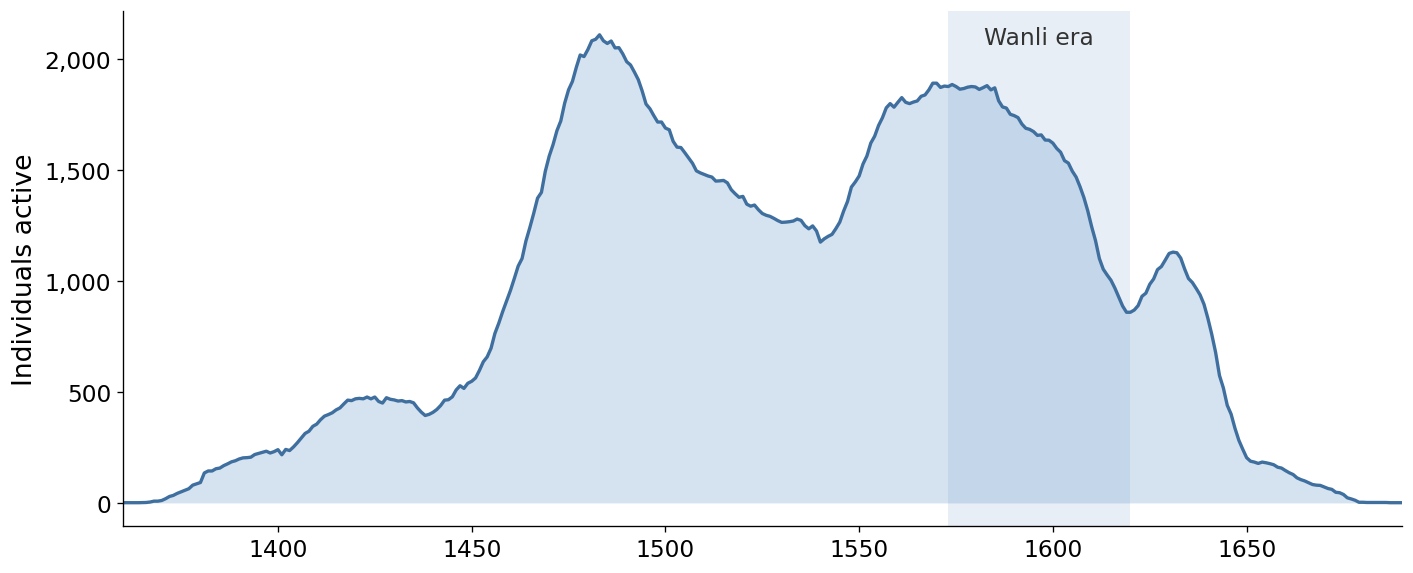

In [11]:
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(ming_per_year['year'], ming_per_year['len'], color=MAIN_COLOR, alpha=0.25, lw=0)
ax.plot(ming_per_year['year'], ming_per_year['len'], color=MAIN_LINE_COLOR)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.text((WANLI_START + WANLI_END) / 2, ax.get_ylim()[1] * 0.97, 'Wanli era', ha='center', va='top', color=TEXT)
ax.set_xlim(ming_per_year['year'].min(), ming_per_year['year'].max())
ax.set_ylabel('Individuals active')
ax.yaxis.set_major_formatter(THOUSANDS)
plt.tight_layout()
plt.show()

### Figure 2: Who was active during the Wanli era, beyond officials
Individuals with a main occupation other than "politician" (officials and individuals without occupation are left out, see the overview). Only active lives overlapping 1573–1620 are kept, so the curve rises and falls at the edges by construction.

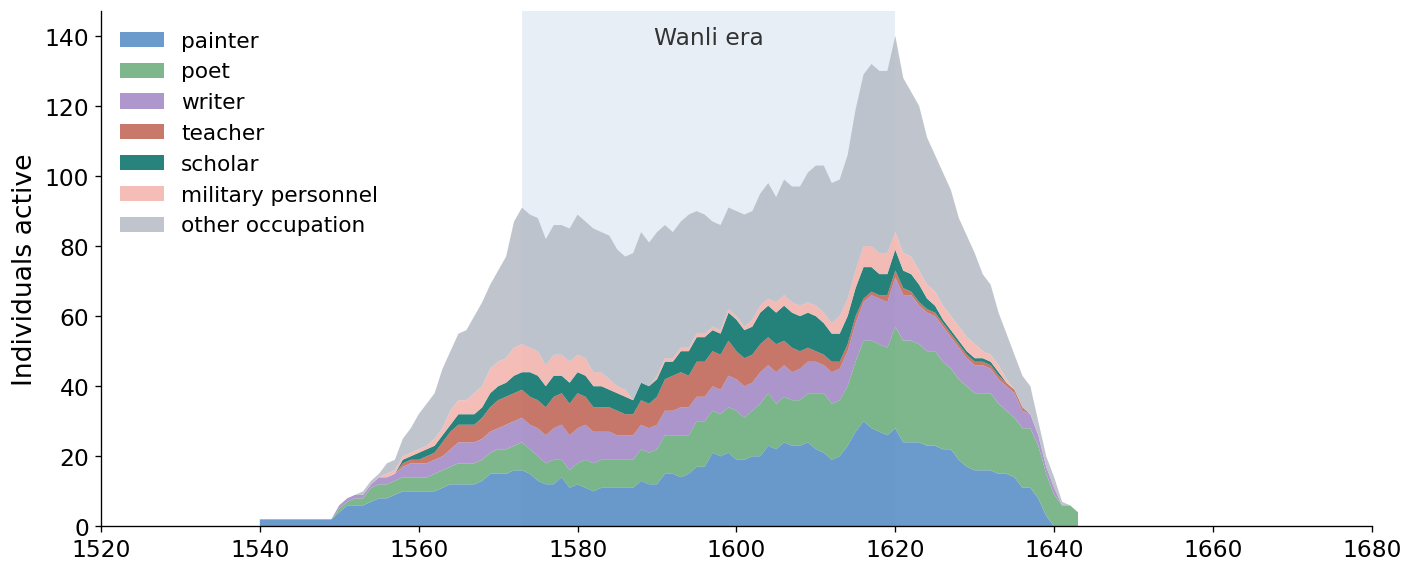

In [12]:
fig, ax = plt.subplots(figsize=FIGSIZE)
groups = active_per_year.columns[1:]
ax.stackplot(active_per_year['year'], *[active_per_year[group] for group in groups],
             labels=groups, colors=[GROUP_COLORS[group] for group in groups], alpha=0.9)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.text((WANLI_START + WANLI_END) / 2, ax.get_ylim()[1] * 0.97, 'Wanli era', ha='center', va='top', color=TEXT)
ax.set_xlim(SERIES_START, SERIES_END)
ax.set_ylabel('Individuals active')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left', fontsize=13)
plt.tight_layout()
plt.show()

### Figure 3: Most common Wikidata occupations
All occupations of each individual are counted.

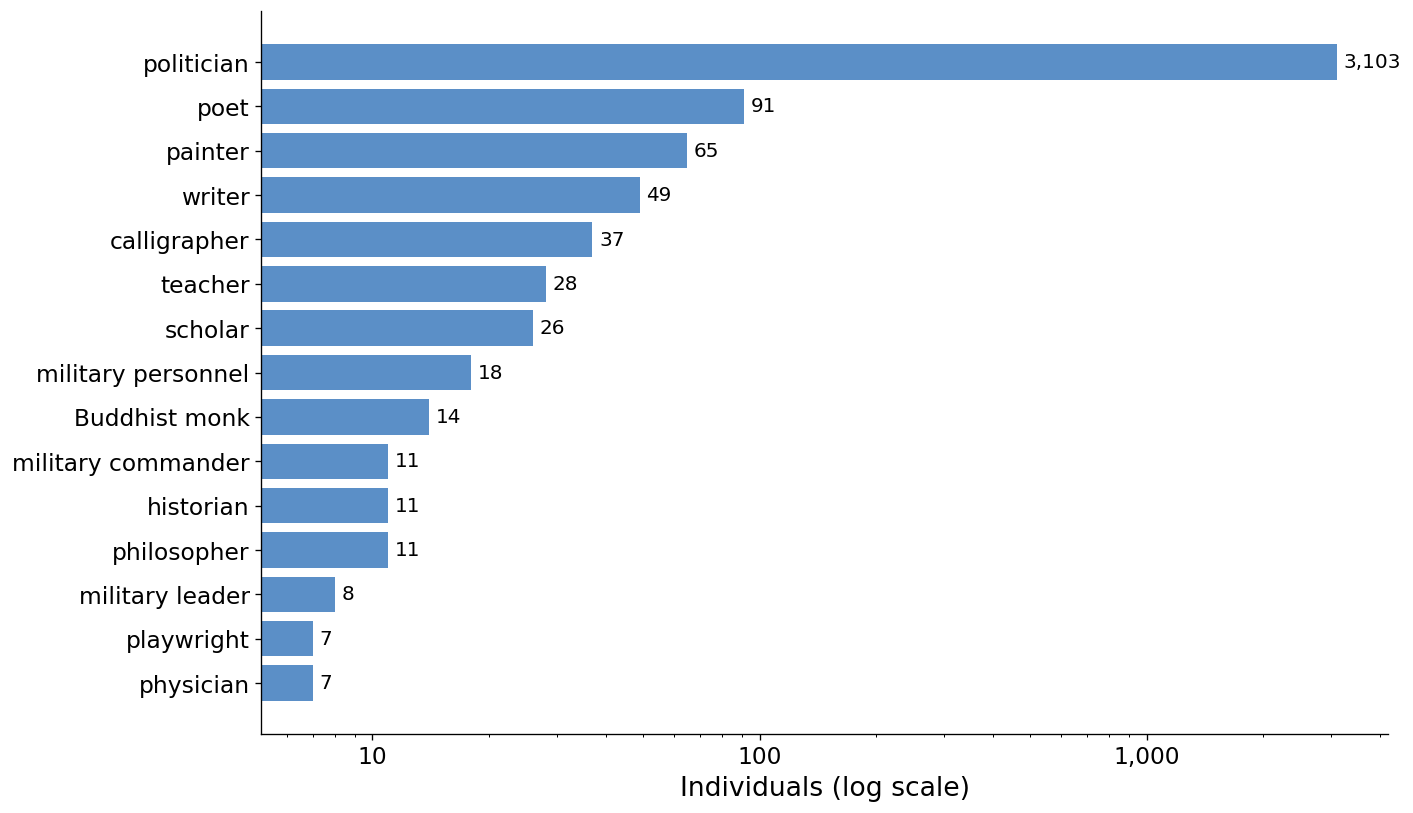

In [13]:
top_occupations = (
    occupations.group_by('occupation').agg(pl.col('qid').n_unique().alias('individuals'))
    .sort('individuals', descending=True).head(TOP_OCCUPATIONS)
    .sort('individuals')
)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(top_occupations['occupation'], top_occupations['individuals'],
               color=MAIN_COLOR)
ax.bar_label(bars, labels=[f'{value:,}' for value in top_occupations['individuals']], padding=4, fontsize=VALUE_LABEL_FONTSIZE)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Individuals (log scale)')
plt.tight_layout()
plt.show()

### Figure 4: The 40 most-linked individuals of the era
Ranked by number of Wikimedia sitelinks (Wikipedia editions and sister projects), shown in brackets. Thin grey line: life (birth to death); thick bar: active life; colour: main occupation.

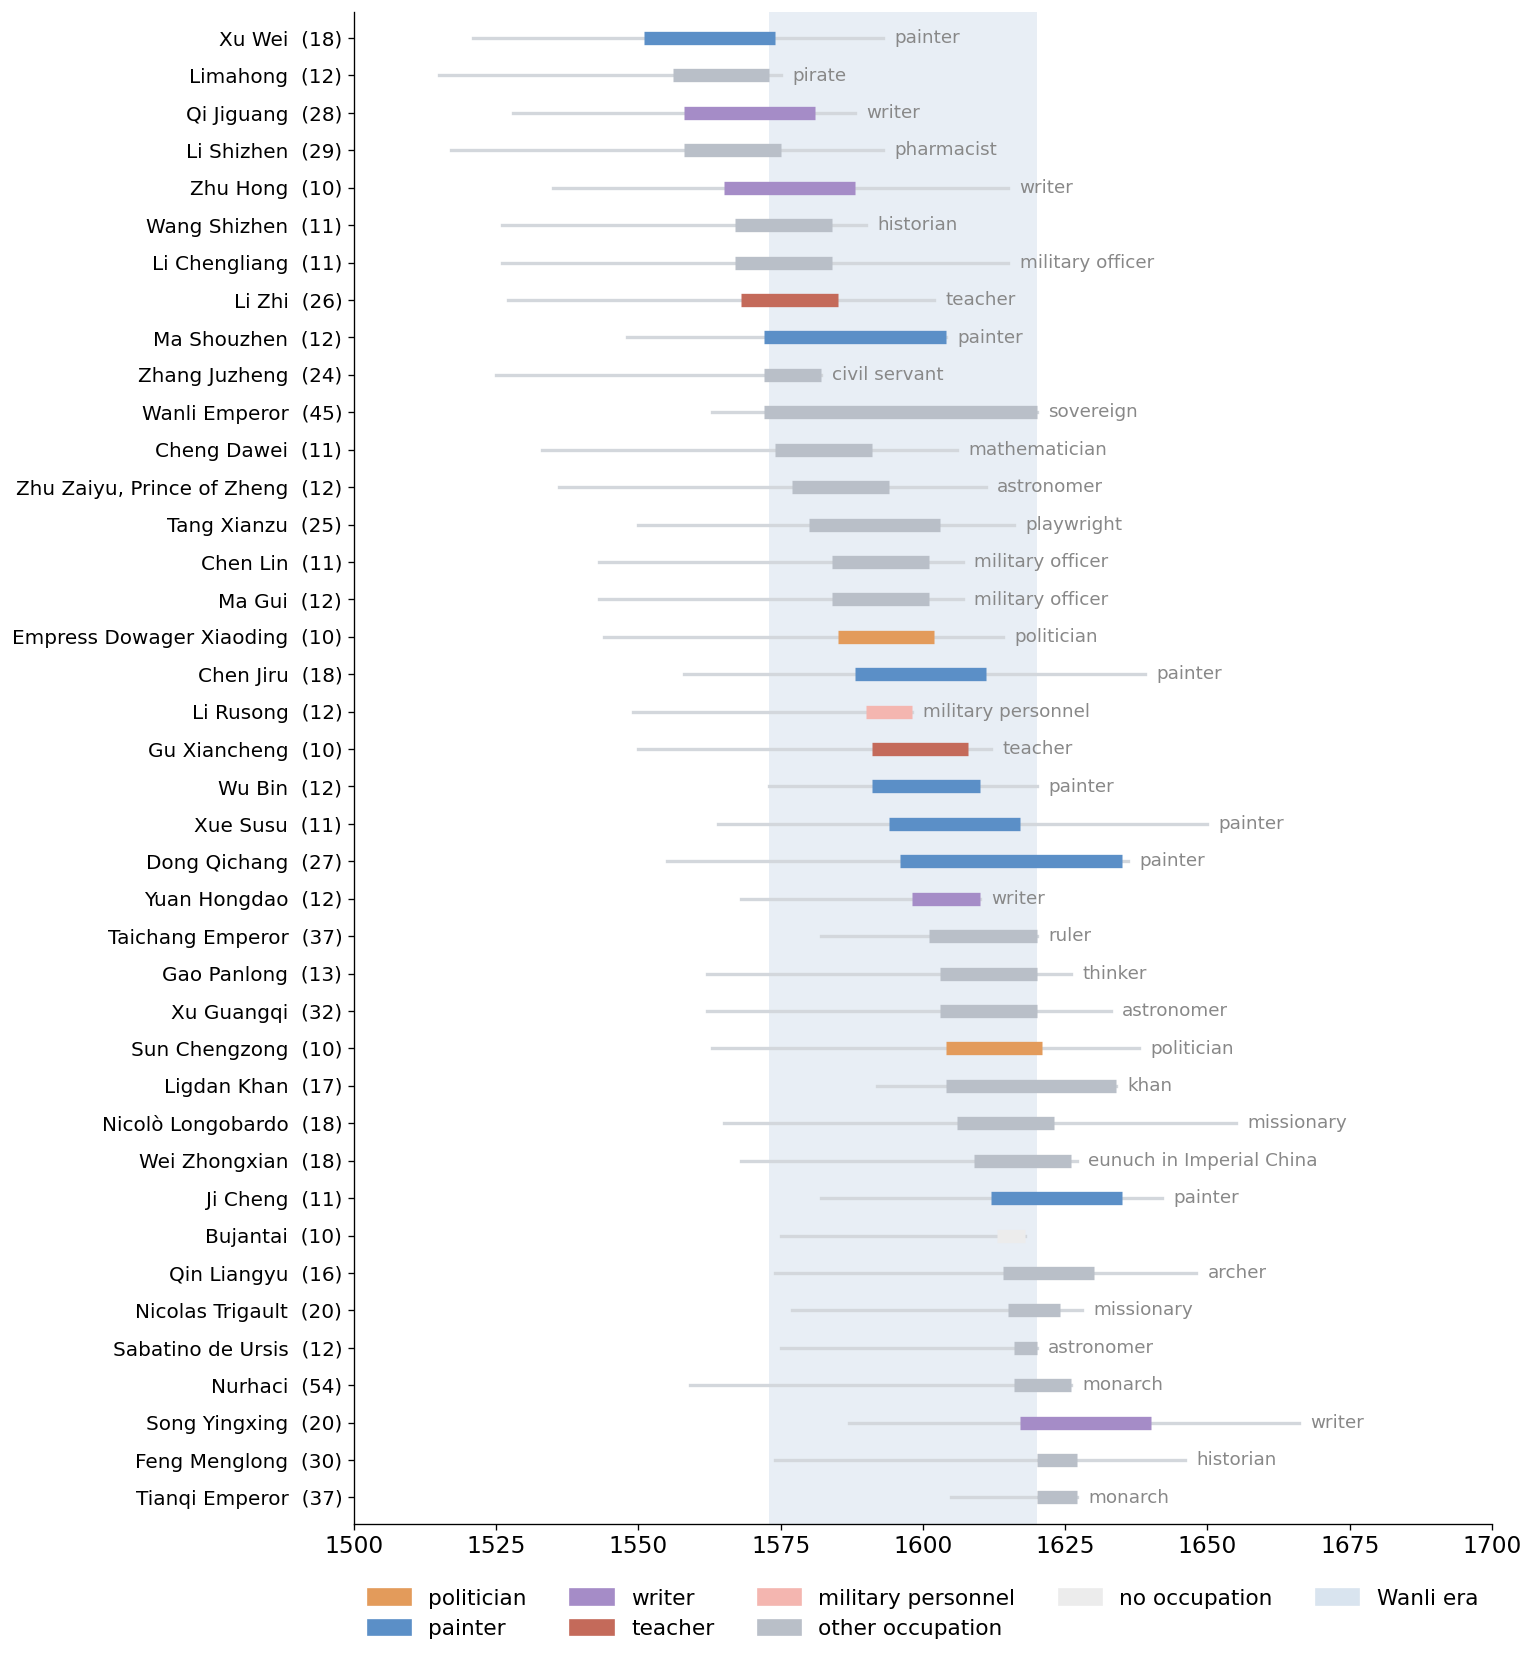

In [14]:
timeline = people.sort('sitelinks', descending=True).head(TOP_TIMELINE).sort('active_start', descending=True)

fig, ax = plt.subplots(figsize=(13, 14))
for position, person in enumerate(timeline.iter_rows(named=True)):
    if person['birth_year'] is not None and person['death_year'] is not None:
        ax.plot([person['birth_year'], person['death_year']], [position, position], color=LIGHT_GREY, lw=2, zorder=1)
    ax.plot([person['active_start'], person['active_end']], [position, position],
            color=GROUP_COLORS[person['group']], lw=8, solid_capstyle='butt', zorder=2)
    ax.text(max(person['active_end'], person['death_year'] or 0) + 2, position, person['main_occupation'] or '',
            va='center', fontsize=POINT_LABEL_FONTSIZE, color=MUTED_TEXT)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.set_yticks(range(timeline.height))
ax.set_yticklabels([f"{name}  ({links})" for name, links in zip(timeline['name'], timeline['sitelinks'])], fontsize=LONG_TICK_LABEL_FONTSIZE)
ax.set_ylim(-0.7, timeline.height - 0.3)
ax.set_xlim(1500, 1700)
present = [group for group in GROUP_ORDER if group in set(timeline['group'])]
ax.legend(handles=[Patch(color=GROUP_COLORS[group], label=group) for group in present] + [Patch(color=PALE_BLUE, label='Wanli era')],
          loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)
plt.tight_layout()
plt.show()

### Figure 5: Birthplaces
Only individuals whose birthplace has coordinates (see the overview). Shaded: Ming territory 1600–1618 (Cliopatria).

221 of 5,296 individuals located


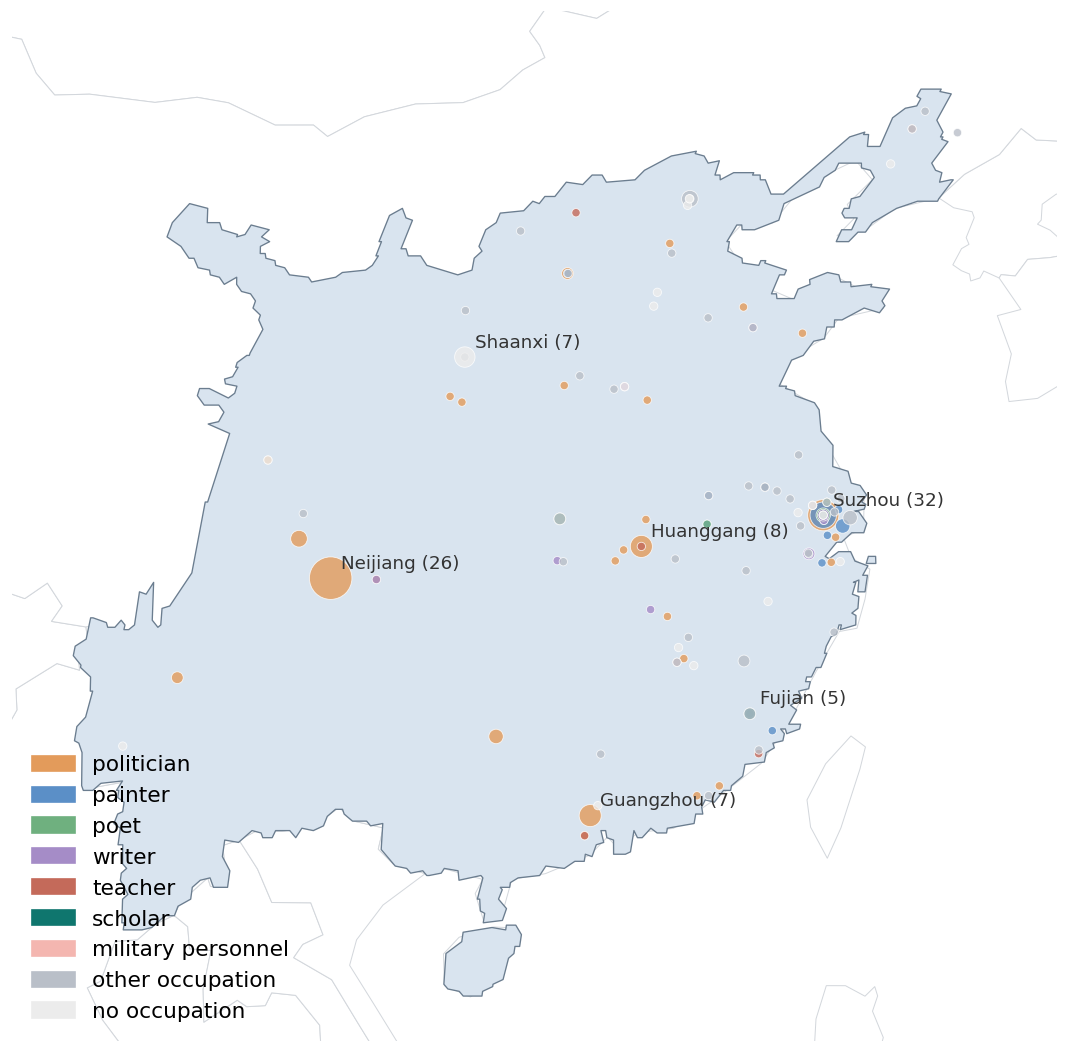

In [15]:
located = people.filter(pl.col('latitude').is_not_null())
birthplace_counts = located.group_by('birthplace', 'latitude', 'longitude', 'group').len()

fig, ax = plt.subplots(figsize=(10, 9))
countries.plot(ax=ax, color='white', edgecolor=LIGHT_GREY, lw=0.6)
ming_shape.plot(ax=ax, color=PALE_BLUE, edgecolor=SLATE, lw=0.8)
for group in GROUP_ORDER:
    subset = birthplace_counts.filter(pl.col('group') == group)
    if subset.height:
        ax.scatter(subset['longitude'], subset['latitude'], s=subset['len'] * 25, color=GROUP_COLORS[group],
                   alpha=0.8, edgecolor='white', lw=0.5, zorder=3)
for place in located.group_by('birthplace', 'latitude', 'longitude').len().sort('len', descending=True).head(6).iter_rows(named=True):
    ax.annotate(f"{place['birthplace']} ({place['len']})", (place['longitude'], place['latitude']),
                xytext=(6, 6), textcoords='offset points', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
ax.set_xlim(*MAP_EXTENT[:2])
ax.set_ylim(*MAP_EXTENT[2:])
ax.set_axis_off()
present = [group for group in GROUP_ORDER if group in set(birthplace_counts['group'])]
ax.legend(handles=[Patch(color=GROUP_COLORS[group], label=group) for group in present], loc='lower left')
print(f'{located.height:,} of {people.height:,} individuals located')
plt.tight_layout()
plt.show()

## Biographies
### The 30 most-linked individuals

In [16]:
def years(start, end):
    return f"{start if start is not None else '?'}–{end if end is not None else '?'}"


def biography_table(frame):
    return pd.DataFrame({
        'name': [f"{name} {original or ''}".strip() for name, original in zip(frame['name'], frame['name_original'])],
        'life': [years(birth, death) for birth, death in zip(frame['birth_year'], frame['death_year'])],
        'active life': [years(start, end) for start, end in zip(frame['active_start'], frame['active_end'])],
        'occupations': frame['occupations'].fill_null('').to_list(),
        'description': frame['description'].fill_null('').to_list(),
        'birthplace': frame['birthplace'].fill_null('').to_list(),
        'sitelinks': frame['sitelinks'].to_list(),
    })


pd.set_option('display.max_colwidth', 90)
biography_table(people.sort('sitelinks', descending=True).head(TOP_BIOGRAPHIES)).style.hide(axis='index')

name,life,active life,occupations,description,birthplace,sitelinks
Nurhaci,1559–1626,1616–1626,monarch,"Jurchen chieftain of Later Jin, founder of Qing Dynasty (1559 - 1626)",Hetu Ala City,54
Wanli Emperor,1563–1620,1572–1620,"sovereign, poet",emperor of the Ming Dynasty (1563-1620),Beijing,45
Taichang Emperor,1582–1620,1601–1620,ruler,15th Emperor of the Ming dynasty,Beijing,37
Tianqi Emperor,1605–1627,1620–1627,monarch,emperor of the Ming Dynasty,Beijing,37
Xu Guangqi,1562–1633,1603–1620,"astronomer, mathematician, translator, writer, politician","late-Ming-dynasty Chinese politician, Scholar, Lay Catholic leader and Servant of God (*1562 – †1633)",Shanghai,32
Feng Menglong,1574–1646,1620–1627,"historian, collector of fairy tales, writer, poet",Chinese writer and poet,Suzhou,30
Li Shizhen,1517–1593,1558–1575,"pharmacist, naturalist, botanist, writer, physician",Chinese polymath and scientist (1517-1593),Qizhou,29
Qi Jiguang,1528–1588,1558–1581,"writer, military personnel",Ming Dynasty general,Shandong,28
Dong Qichang,1555–1636,1596–1635,"painter, art theorist, art historian, calligrapher, writer, poet, politician","Chinese painter, scholar, calligrapher, and art theorist (1555-1636)",Songjiang,27
Li Zhi,1527–1602,1568–1585,"teacher, philosopher",Chinese philosopher (1527–1602),Jinjiang,26


### Top 5 per main occupation

In [17]:
for group in GROUP_ORDER:
    subset = people.filter(pl.col('group') == group).sort('sitelinks', descending=True).head(5)
    print(f'{group}: {people.filter(pl.col("group") == group).height:,} individuals')
    display(biography_table(subset).style.hide(axis='index'))

politician: 3,034 individuals


name,life,active life,occupations,description,birthplace,sitelinks
Sun Chengzong,1563–1638,1604–1621,politician,Grand Secretary of the late Ming Dynasty,Gaoyang County,10
Empress Dowager Xiaoding,1544–1614,1585–1602,politician,mother of the Wanli Emperor; CBDB ID=67555,,10
Shen Shixing,1535–1614,1576–1593,politician,Ming dynasty person CBDB=123973 (1535–1614),Suzhou,9
Cuyen,1580–1615,1615–1615,politician,Manchu prince (1580-1615),,9
Shen Yiguan,1531–1617,1572–1589,politician,Ming dynasty person CBDB = 124055,,7


painter: 65 individuals


name,life,active life,occupations,description,birthplace,sitelinks
Dong Qichang,1555–1636,1596–1635,"painter, art theorist, art historian, calligrapher, writer, poet, politician","Chinese painter, scholar, calligrapher, and art theorist (1555-1636)",Songjiang,27
Chen Jiru,1558–1639,1588–1611,"painter, autobiographer, calligrapher, writer, poet",Chinese artist (1558-1639),Songjiang,18
Xu Wei,1521–1593,1551–1574,"painter, playwright, calligrapher, writer, poet, literary scholar, strategist",Ming Dynasty painter (1521-1593),Shaoxing,18
Ma Shouzhen,1548–1604,1572–1604,"painter, changji, composer, poet","Chinese courtesan, painter, poet, and composer (1548-1604)",Nanjing,12
Wu Bin,1573–1620,1591–1610,"painter, writer, poet",Chinese painter (1573-1620),Putian,12


poet: 52 individuals


name,life,active life,occupations,description,birthplace,sitelinks
Lü Tiancheng,1580–1618,1610–1618,poet,,,6
Zhong Xing,1574–1625,1604–1625,"poet, politician",Ming dynasty politician,Hubei,6
Yuan Zhongdao,1570–1624,1600–1623,"poet, politician",Chinese poet (1570-1624),Hubei,5
Xia Yunyi,1585–1645,1615–1638,"poet, politician",Ming dynasty politician (1596–1645),,5
Shisheng Tang,1551–1636,1581–1604,poet,Ming dynasty person CBDB = 129447,,2


... (8 outputs left out)

other occupation: 140 individuals


name,life,active life,occupations,description,birthplace,sitelinks
Nurhaci,1559–1626,1616–1626,monarch,"Jurchen chieftain of Later Jin, founder of Qing Dynasty (1559 - 1626)",Hetu Ala City,54
Wanli Emperor,1563–1620,1572–1620,"sovereign, poet",emperor of the Ming Dynasty (1563-1620),Beijing,45
Taichang Emperor,1582–1620,1601–1620,ruler,15th Emperor of the Ming dynasty,Beijing,37
Tianqi Emperor,1605–1627,1620–1627,monarch,emperor of the Ming Dynasty,Beijing,37
Xu Guangqi,1562–1633,1603–1620,"astronomer, mathematician, translator, writer, politician","late-Ming-dynasty Chinese politician, Scholar, Lay Catholic leader and Servant of God (*1562 – †1633)",Shanghai,32


no occupation: 1,911 individuals


name,life,active life,occupations,description,birthplace,sitelinks
Bujantai,1575–1618,1613–1618,,Jurchen chieftain,,10
Empress Xiaoan,1536–1596,1574–1593,,Ming Dynasty empress,,9
Šurhaci,1564–1611,1602–1611,,Jurchen leader,Ming dynasty,9
Empress Xiaoduanxian,1565–1620,1603–1620,,Ming Dynasty empress,Yuyao City,9
Taksi,1543–1582,1581–1582,,Jurchen chieftain and father of Nurhaci,,8


### Women of the era

In [18]:
women = people.filter(pl.col('is_female')).sort('sitelinks', descending=True)
print(f'{women.height} women')
biography_table(women).style.hide(axis='index')

47 women


name,life,active life,occupations,description,birthplace,sitelinks
Qin Liangyu,1574–1648,1614–1630,archer,Chinese female general in Ming dynasty,,16
Ma Shouzhen,1548–1604,1572–1604,"painter, changji, composer, poet","Chinese courtesan, painter, poet, and composer (1548-1604)",Nanjing,12
Xue Susu,1564–1650,1594–1617,"painter, embroiderer, changji, poet","Chinese prostitute, poet, artist, mounted archer, and Buddhist nun (c. 1564-1650)",Suzhou,11
Empress Dowager Xiaoding,1544–1614,1585–1602,politician,mother of the Wanli Emperor; CBDB ID=67555,,10
Empress Xiaoan,1536–1596,1574–1593,,Ming Dynasty empress,,9
Empress Xiaoduanxian,1565–1620,1603–1620,,Ming Dynasty empress,Yuyao City,9
Qiu Zhu,1525–1585,1555–1578,painter,Chinese Ming Dynasty painter (fl. 1565–1585),Taicang,9
Empress Xiaocigao,1575–1603,1603–1603,,empress of the Qing dynasty,,8
Noble Consort Zheng,1565–1630,1603–1622,,Wanli Emperor's concubine,Daxing District,8
Lin Xue,1582–1642,1612–1635,painter,Chinese painter,Fujian,7


### A random sample of the long tail
Most individuals come from the China Biographical Database (CBDB): no sitelink and a description that is only an identifier.

In [19]:
long_tail = people.filter(pl.col('sitelinks') == 0).sample(10, seed=SEED)
biography_table(long_tail).style.hide(axis='index')

name,life,active life,occupations,description,birthplace,sitelinks
Zhou Hao,1552–1611,1590–1609,,Ming dynasty person CBDB = 206820,,0
Wu Yuyan,1535–1594,1573–1592,,Ming dynasty person CBDB = 205359,,0
Xie Zonglun,1533–1592,1571–1590,,Ming dynasty person CBDB = 205682,,0
Zhu Jiao,1532–1591,1570–1589,,Ming dynasty person CBDB = 205268,,0
Lin Tingzhang,1531–1590,1569–1588,,Ming dynasty person CBDB = 203908,,0
Li Pan,1549–1608,1587–1606,,Ming dynasty person CBDB = 206646,,0
Yao Kang,1578–1653,1616–1635,,Qing dynasty person CBDB = 85474,,0
Fang Huan,1540–1599,1578–1597,,Ming dynasty person CBDB = 205725,,0
Zhang ??,1528–1587,1566–1585,,Ming dynasty person CBDB = 205151,,0
Li Youji,1551–1610,1589–1608,,Ming dynasty person CBDB=207003,,0


## Check: who are these individuals?
### Where the dates come from

In [20]:
date_sources = (
    people
    .with_columns(
        pl.col('birth_source').fill_null('missing'),
        pl.col('death_source').fill_null('missing'),
        (pl.col('active_end') - pl.col('active_start')).alias('active_span'),
    )
    .group_by('birth_source', 'death_source')
    .agg(pl.len().alias('individuals'), pl.col('active_span').median().alias('median_active_span'))
    .with_columns((pl.col('individuals') / people.height * 100).round(1).alias('share_%'))
    .sort('individuals', descending=True)
)
assert date_sources['individuals'].sum() == people.height
date_sources

birth_source,death_source,individuals,median_active_span,share_%
str,str,u32,f64,f64
"""wikidata""","""estimated""",3974,17.0,75.0
"""wikidata""","""wikidata""",1006,17.0,19.0
"""estimated""","""wikidata""",311,19.0,5.9
"""missing""","""missing""",5,0.0,0.1


In [21]:
print('Most common active-life lengths (years):')
people.select((pl.col('active_end') - pl.col('active_start')).alias('active_span'))['active_span'].value_counts(sort=True).head(5)

Most common active-life lengths (years):


active_span,count
i64,u32
17,3060
19,1831
23,141
0,34
16,27


### Who they are

**Mostly officials from the CBDB.** About 5,300 individuals were active under the Wanli Emperor. Most come from the China Biographical Database (CBDB). In Wikidata they are almost always "politician", which means a degree-holder or civil official. Four in five have only a CBDB identifier as their description, and about a third have no Wikipedia or other Wikimedia page. About 1,900 have no occupation at all. For these people, Cultura records that they existed and when, but not what they did.

**A small, well-known elite.** Only about 120 individuals have five or more sitelinks, and they give the familiar picture of the late Ming:
- *The court:* the Wanli, Taichang and Tianqi emperors, empresses and consorts (Noble Consort Zheng), the eunuch Wei Zhongxian.
- *Statesmen:* the Grand Secretary Zhang Juzheng, whose reforms opened the reign, and the Donglin academics Gu Xiancheng and Gao Panlong.
- *Science and learning:* Li Shizhen (pharmacology), Song Yingxing (technology), Zhu Zaiyu (music theory and mathematics), Xu Guangqi (astronomy and mathematics, a Catholic convert).
- *Letters and arts:* Tang Xianzu (theatre), Feng Menglong (vernacular stories), Yuan Hongdao (poetry), the painters Dong Qichang, Chen Jiru, Xu Wei and Wu Bin, and the philosopher Li Zhi.
- *War:* the generals Qi Jiguang, Li Chengliang and Li Rusong, and the pirate Limahong.

**The edges of the empire are in the set.** The Jesuits Nicolas Trigault, Nicolò Longobardo and Sabatino de Ursis were born in Europe but are matched to Ming China. So are the Jurchen leaders Nurhaci, Šurhaci, Bujantai and Giocangga, and the Mongol Ligdan Khan. Nurhaci founded the Later Jin in 1616, yet his active life (1616–1626) is still matched to the Ming polity. Whether such borderland figures belong to Ming China should be decided before using this set for comparisons.

**Women are rare (47, under 1%).** They fall into two kinds. On one side, court women (empresses, consorts, the Wanli Emperor's mother) and famous artists: the courtesan-painters Ma Shouzhen and Xue Susu, the painter-poet Fang Weiyi, and the general Qin Liangyu. On the other, CBDB women poets known only as "wife of …".

**The dates are mostly estimated, which shapes the figures.** Three quarters of the individuals have a Wikidata birth year and an *estimated* death. Above all, 99.4% have an *estimated* active life, even when both dates are known: birth + a cohort median age (38 or 41) to birth + another (58 or 60). This is why most active lives last exactly 17 or 19 years. The curves in Figures 1–2 therefore follow the birth dates, smoothed by a fixed window. They are not the real career lengths: Xu Guangqi's active life, for instance, ends in 1620 although he served until his death in 1633.